In [1]:
!pip install gower

In [2]:
!pip install kmedoids

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
reviews=pd.read_excel("Hotel Feedback Details.xlsx")
hotels=pd.read_excel("Hotel List.xlsx")
customers=pd.read_excel("Customer.xlsx")

reviews.head()

In [5]:
reviews.columns

In [6]:
df=reviews.merge(hotels,left_on= "Hotel ",right_on="ID",how="left")

df=df.drop(columns=["ID"])
df.head() 

In [7]:
df.columns

In [8]:
 df=df.merge(customers,left_on= "Booking No",right_on="Tour no.",how="left")

df.head()

In [9]:
df.columns

In [10]:
df=df.drop(columns=["Tour no."])
df.head()

In [11]:
df.columns.tolist()

In [12]:
new_order = [
    "Booking No",
    "Hotel ",
    "Hotel Name",
    "Nationality",
    "Welcome / Check in",
    "Standard of the room",
    "Cleanliness",
    "Restaurant Service",
    "Quality Meals",
    "Attentiveness / Friendliness of Hotel staffs",
    "Overall Rating"
]

df = df[new_order]

df.head()

In [13]:
df.info()

In [14]:
df.isnull().sum()

In [15]:
rating_columns = [
    "Welcome / Check in",
    "Standard of the room",
    "Cleanliness",
    "Restaurant Service",
    "Quality Meals",
    "Attentiveness / Friendliness of Hotel staffs",
    "Overall Rating"
]


for col in rating_columns:
    df[col] = df[col].fillna(df[col].mode()[0])

In [16]:
#Duplicate records identified using combination of booking number and hotel ID
df = df.drop_duplicates(subset=["Booking No", "Hotel "])

In [17]:
for col in rating_columns:
    print(col)
    print(df[col].unique())
    print()

Welcome / Check in
['GOOD' 'EXCELLENT' 'SATISFACTORY' 'UNACCEPTABLE' 'POOR' 'select']

Standard of the room
['GOOD' 'EXCELLENT' 'SATISFACTORY' 'UNACCEPTABLE' 'POOR' 'select']

Cleanliness
['EXCELLENT' 'GOOD' 'POOR' 'SATISFACTORY' 'UNACCEPTABLE' 'select']

Restaurant Service
['GOOD' 'EXCELLENT' 'SATISFACTORY' 'POOR' 'UNACCEPTABLE' 'select']

Quality Meals
['GOOD' 'EXCELLENT' 'SATISFACTORY' 'POOR' 'UNACCEPTABLE' 'select']

Attentiveness / Friendliness of Hotel staffs
['GOOD' 'EXCELLENT' 'SATISFACTORY' 'POOR' 'UNACCEPTABLE' 'select']

Overall Rating
['GOOD' 'EXCELLENT' 'SATISFACTORY' 'POOR' 'UNACCEPTABLE' 'select']



In [18]:
for col in rating_columns:
    df[col] = df[col].replace("select", np.nan)

In [19]:
df[rating_columns].isnull().sum()

Welcome / Check in                              8
Standard of the room                            7
Cleanliness                                     8
Restaurant Service                              9
Quality Meals                                   7
Attentiveness / Friendliness of Hotel staffs    8
Overall Rating                                  8
dtype: int64

In [20]:
for col in rating_columns:
    df[col] = df[col].fillna(df[col].mode()[0])

In [21]:
#Ordinal encoding for the oridnal ratings
rating_map = {
    "UNACCEPTABLE": 0,
    "POOR": 1,
    "SATISFACTORY": 2,
    "GOOD": 3,
    "EXCELLENT": 4
}

for col in rating_columns:
    df[col] = df[col].map(rating_map).astype(int)

df.head()

In [22]:
df.to_csv("final_dataset.csv", index=False)

In [23]:
dataset_summary = pd.DataFrame({
    "Measure": [
        "Total Reviews",
        "Number of Hotels",
        "Number of Nationalities",
        "Number of Service Features"
    ],
    "Value": [
        len(df),
        df["Hotel Name"].nunique(),
        df["Nationality"].nunique(),
        len(rating_columns)-1
    ]
})

dataset_summary

,Measure,Value
0,Total Reviews,3230
1,Number of Hotels,161
2,Number of Nationalities,12
3,Number of Service Features,6


In [24]:
#Top10 nationality
nationality_count = (
    df["Nationality"]
    .value_counts()
    .head(10)
)

nationality_count

Nationality
German      1332
British     1261
Dutch        189
French       178
Italian      101
Belgian       68
Swiss         43
Denmark       27
Austrian      13
Spanish        9
Name: count, dtype: int64

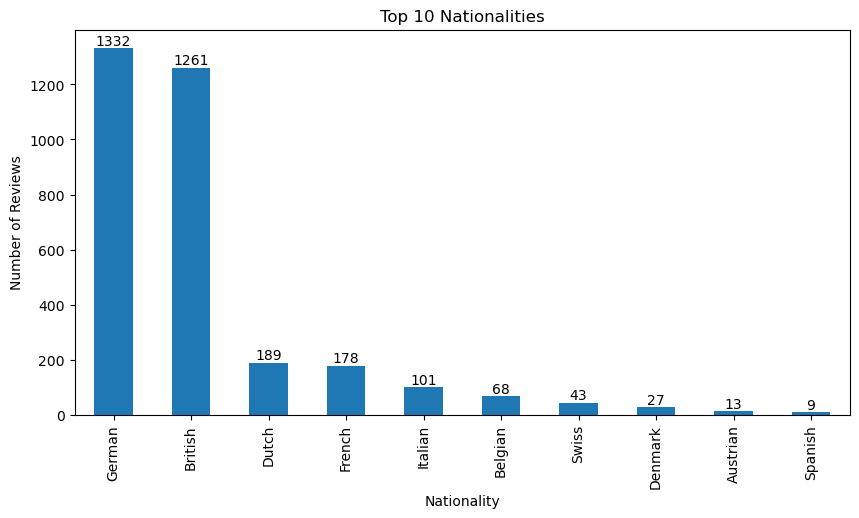

In [25]:
plt.figure(figsize=(10,5))
ax = nationality_count.plot(kind="bar")

plt.title("Top 10 Nationalities")
plt.xlabel("Nationality")
plt.ylabel("Number of Reviews")

for container in ax.containers:
    ax.bar_label(container)


plt.savefig("Nationality_Distribution.png", dpi=300, bbox_inches="tight")
plt.show()


In [26]:
rating_labels = {
    0: "Unacceptable",
    1: "Poor",
    2: "Satisfactory",
    3: "Good",
    4: "Excellent"
}
 
central_tendency_summary = pd.DataFrame({
    "Mean": df[rating_columns].mean().round(2),
    "Median": df[rating_columns].median(),
    "Mode": df[rating_columns].mode().iloc[0]
})
 
central_tendency_summary["Mode (label)"] = central_tendency_summary["Mode"].map(rating_labels)
central_tendency_summary = central_tendency_summary.sort_values(by="Median", ascending=False)
 
central_tendency_summary.to_excel("central_tendency_summary.xlsx")
central_tendency_summary

,Mean,Median,Mode,Mode (label)
Welcome / Check in,3.64,4.0,4,Excellent
Standard of the room,3.44,4.0,4,Excellent
Cleanliness,3.51,4.0,4,Excellent
Restaurant Service,3.50,4.0,4,Excellent
Quality Meals,3.41,4.0,4,Excellent
Attentiveness / Friendliness of Hotel staffs,3.63,4.0,4,Excellent
Overall Rating,3.45,4.0,4,Excellent


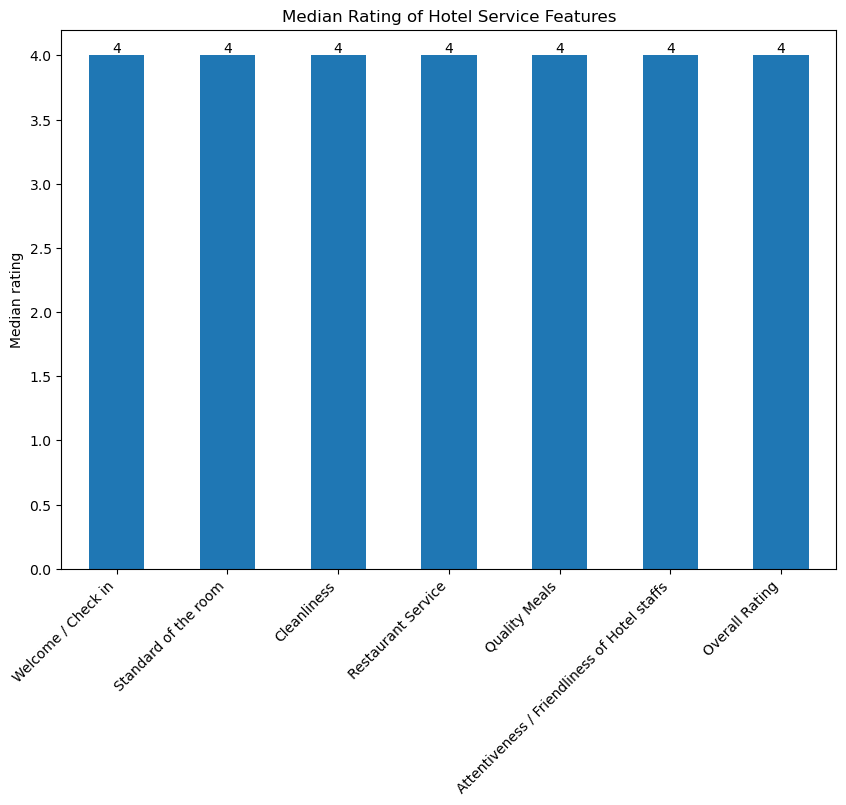

In [27]:
plt.figure(figsize=(10,7))
ax = central_tendency_summary["Median"].plot(kind="bar")

plt.title("Median Rating of Hotel Service Features")
plt.ylabel("Median rating")
plt.xticks(rotation=45, ha="right")
for container in ax.containers:
    ax.bar_label(container)

plt.savefig("Median Rating of Hotel Service Features.png", dpi=300, bbox_inches="tight")
plt.show()


<Figure size 1000x600 with 0 Axes>

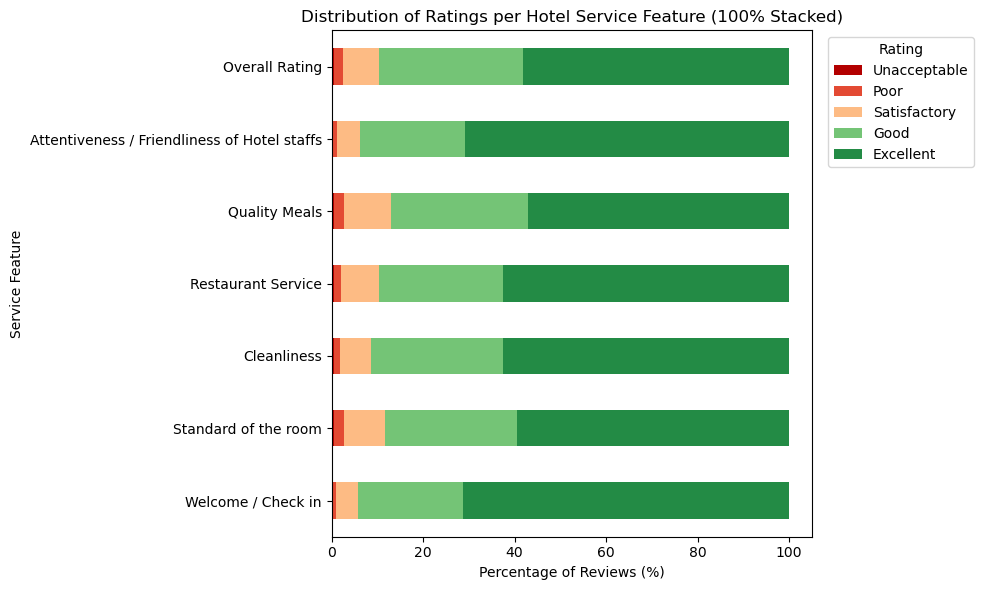

In [28]:
dist_pct = pd.DataFrame({
    col: df[col].value_counts(normalize=True).reindex([0, 1, 2, 3, 4], fill_value=0) * 100
    for col in rating_columns
}).T
 
dist_pct.columns = [rating_labels[c] for c in dist_pct.columns]
dist_pct = dist_pct[["Unacceptable", "Poor", "Satisfactory", "Good", "Excellent"]]
 
colors = ["#b30000", "#e34a33", "#fdbb84", "#74c476", "#238b45"]
 
plt.figure(figsize=(10, 6))
ax = dist_pct.plot(kind="barh", stacked=True, color=colors, figsize=(10, 6))
 
plt.title("Distribution of Ratings per Hotel Service Feature (100% Stacked)")
plt.xlabel("Percentage of Reviews (%)")
plt.ylabel("Service Feature")
plt.legend(title="Rating", bbox_to_anchor=(1.02, 1), loc="upper left")
 
plt.tight_layout()
plt.savefig("Rating Distribution per Service Feature (Stacked).png", dpi=300, bbox_inches="tight")
plt.show()

In [29]:
#Correlation between Service features using sparman correlation
service_columns = [
    "Welcome / Check in",
    "Standard of the room",
    "Cleanliness",
    "Restaurant Service",
    "Quality Meals",
    "Attentiveness / Friendliness of Hotel staffs",
    "Overall Rating"
]


correlation = df[service_columns].corr(method="spearman")

correlation

,Welcome / Check in,Standard of the room,Cleanliness,Restaurant Service,Quality Meals,Attentiveness / Friendliness of Hotel staffs,Overall Rating
Welcome / Check in,1.000000,0.528205,0.549087,0.568501,0.477410,0.635866,0.620809
Standard of the room,0.528205,1.000000,0.723443,0.528707,0.507920,0.475403,0.700950
Cleanliness,0.549087,0.723443,1.000000,0.560778,0.520379,0.527388,0.692136
Restaurant Service,0.568501,0.528707,0.560778,1.000000,0.731060,0.668755,0.740072
Quality Meals,0.477410,0.507920,0.520379,0.731060,1.000000,0.549290,0.688821
Attentiveness / Friendliness of Hotel staffs,0.635866,0.475403,0.527388,0.668755,0.549290,1.000000,0.675066
Overall Rating,0.620809,0.700950,0.692136,0.740072,0.688821,0.675066,1.000000


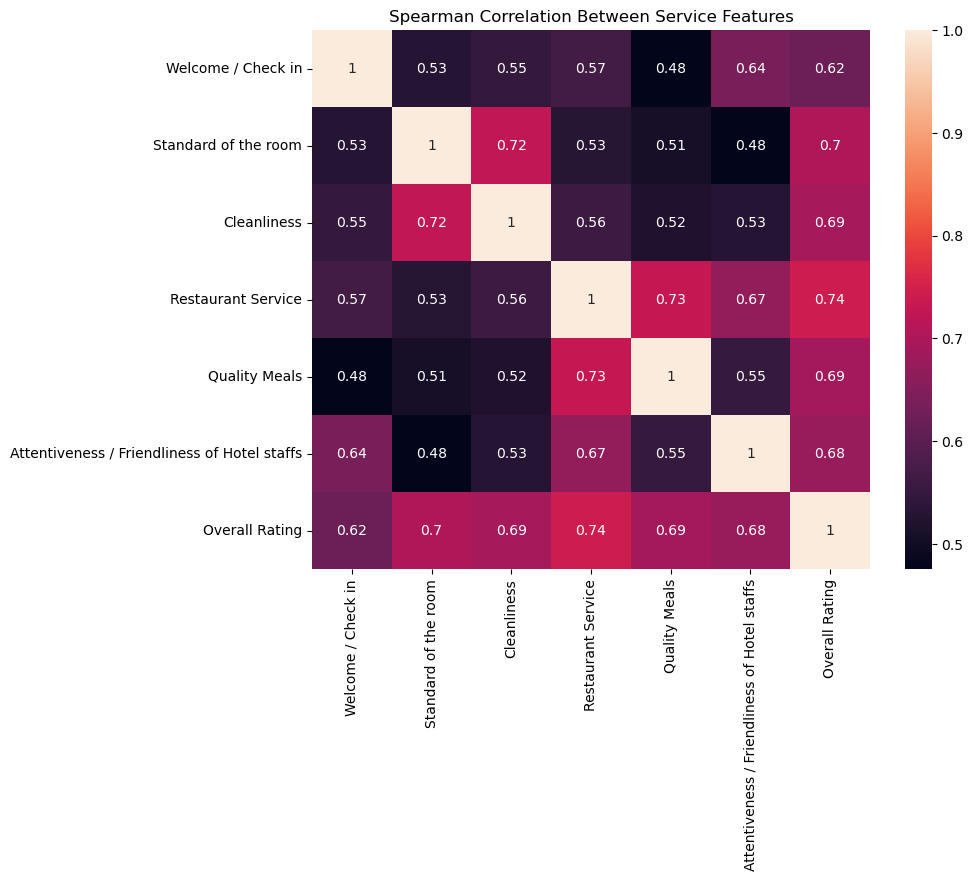

In [30]:
plt.figure(figsize=(9,7))

sns.heatmap(
    correlation,
    annot=True
)

plt.title("Spearman Correlation Between Service Features")

plt.savefig("Spearman Correlation Between Service Features.png", dpi=300, bbox_inches="tight")

plt.show()


In [31]:
cluster_features = [
    "Welcome / Check in",
    "Standard of the room",
    "Cleanliness",
    "Restaurant Service",
    "Quality Meals",
    "Attentiveness / Friendliness of Hotel staffs"
]


X = df[cluster_features]

X.head()

,Welcome / Check in,Standard of the room,Cleanliness,Restaurant Service,Quality Meals,Attentiveness / Friendliness of Hotel staffs
0,3,3,4,3,3,3
1,3,3,3,3,3,3
2,3,3,3,3,3,3
3,4,3,3,4,4,4
4,4,3,4,3,2,3


In [32]:
import kmedoids
from scipy.stats import rankdata
from sklearn.metrics import silhouette_score, davies_bouldin_score

In [33]:
X_raw = X.copy()
X_raw.head()

,Welcome / Check in,Standard of the room,Cleanliness,Restaurant Service,Quality Meals,Attentiveness / Friendliness of Hotel staffs
0,3,3,4,3,3,3
1,3,3,3,3,3,3
2,3,3,3,3,3,3
3,4,3,3,4,4,4
4,4,3,4,3,2,3


In [34]:
#Vectorised Gower -style distance function

def ordinal_gower_metric_vectorized(X):
    X = np.asarray(X, dtype=float)
    n, p = X.shape
 
    ranges = np.nanmax(X, axis=0) - np.nanmin(X, axis=0)
    ranges[ranges == 0] = 1  # avoid division by zero for constant columns
 
    X_normalized = X / ranges
 
    # Pairwise absolute differences for all feature pairs at once via
    # broadcasting: (n, 1, p) - (1, n, p) -> (n, n, p)
    diffs = np.abs(X_normalized[:, None, :] - X_normalized[None, :, :])
 
    # Average across the p features -> (n, n) distance matrix
    distance_matrix = diffs.mean(axis=2)
 
    return distance_matrix

In [35]:
# DISTANCE 1: Standard Gower Distance (on raw ordinal codes)

gower_dist = ordinal_gower_metric_vectorized(X_raw)
print("Gower distance matrix shape:", gower_dist.shape)

Gower distance matrix shape: (3230, 3230)


k=2 -> Silhouette Score: 0.5991
k=3 -> Silhouette Score: 0.5650
k=4 -> Silhouette Score: 0.4982
k=5 -> Silhouette Score: 0.4998
k=6 -> Silhouette Score: 0.4922
k=7 -> Silhouette Score: 0.4696
k=8 -> Silhouette Score: 0.4746


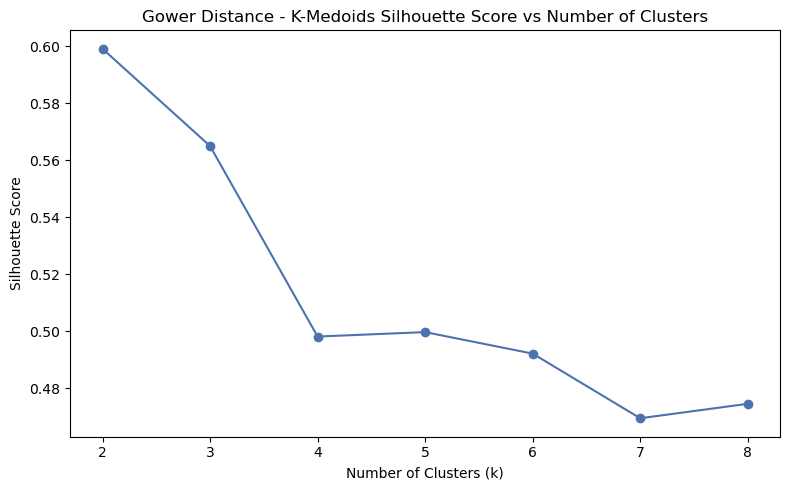

In [36]:
#Choose k for Gower-based K-Medoids using silhouette score ---
gower_scores = {}
 
for k in range(2, 9):
    result = kmedoids.pam(gower_dist, k)
    labels = result.labels
    score = silhouette_score(gower_dist, labels, metric="precomputed")
    gower_scores[k] = score
    print(f"k={k} -> Silhouette Score: {score:.4f}")
 
plt.figure(figsize=(8, 5))
plt.plot(list(gower_scores.keys()), list(gower_scores.values()), marker="o", color="#4C72B0")
plt.title("Gower Distance - K-Medoids Silhouette Score vs Number of Clusters")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.tight_layout()
plt.savefig("Gower KMedoids Silhouette Selection.png", dpi=300, bbox_inches="tight")
plt.show()
 

In [37]:
# Fit final Gower K-Medoids model with chosen k ---
k_gower = max(gower_scores, key=gower_scores.get)
print("Chosen number of clusters for Gower K-Medoids:", k_gower)
 
gower_result = kmedoids.pam(gower_dist, k_gower)
gower_labels = gower_result.labels
 
gower_silhouette = silhouette_score(gower_dist, gower_labels, metric="precomputed")

gower_db = davies_bouldin_score(X_raw, gower_labels)
 
print(f"Gower K-Medoids (k={k_gower}) -> Silhouette: {gower_silhouette:.4f}, Davies-Bouldin: {gower_db:.4f}")
 
df["Gower_Cluster"] = gower_labels

Chosen number of clusters for Gower K-Medoids: 2
Gower K-Medoids (k=2) -> Silhouette: 0.5991, Davies-Bouldin: 0.9645


In [38]:
# DISTANCE 2: Podani's Ordinal Extension of Gower Distance

X_ranked = X_raw.apply(lambda col: rankdata(col, method="average"))
X_ranked.head()

,Welcome / Check in,Standard of the room,Cleanliness,Restaurant Service,Quality Meals,Attentiveness / Friendliness of Hotel staffs
0,558.5,844.0,2221.5,772.0,903.5,571.5
1,558.5,844.0,746.0,772.0,903.5,571.5
2,558.5,844.0,746.0,772.0,903.5,571.5
3,2081.0,844.0,746.0,2221.0,2310.0,2085.5
4,2081.0,844.0,2221.5,772.0,254.5,571.5


In [39]:
# Compute the Podani distance matrix
podani_dist = ordinal_gower_metric_vectorized(X_ranked.values)
print("Podani distance matrix shape:", podani_dist.shape)

Podani distance matrix shape: (3230, 3230)


k=2 -> Silhouette Score: 0.6321
k=3 -> Silhouette Score: 0.5509
k=4 -> Silhouette Score: 0.5726
k=5 -> Silhouette Score: 0.5258
k=6 -> Silhouette Score: 0.5352
k=7 -> Silhouette Score: 0.5335
k=8 -> Silhouette Score: 0.5448


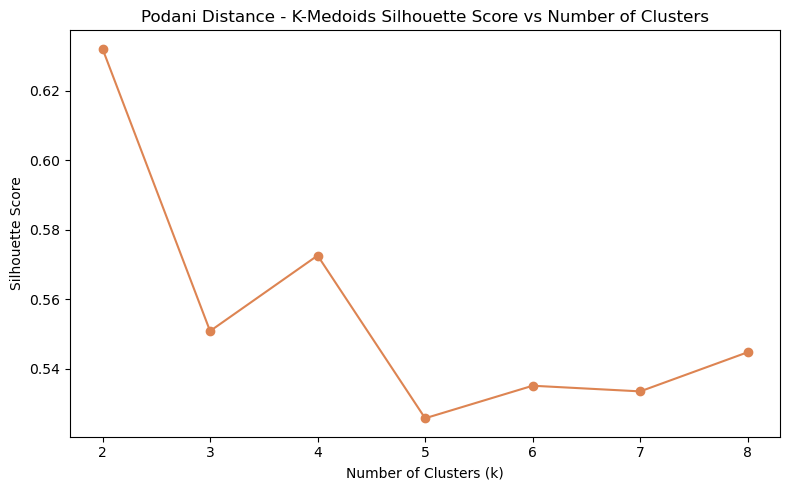

In [40]:
#Choose k for Podani-based K-Medoids using silhouette score ---

podani_scores = {}
 
for k in range(2, 9):
    result = kmedoids.pam(podani_dist, k)
    labels = result.labels
    score = silhouette_score(podani_dist, labels, metric="precomputed")
    podani_scores[k] = score
    print(f"k={k} -> Silhouette Score: {score:.4f}")
 
plt.figure(figsize=(8, 5))
plt.plot(list(podani_scores.keys()), list(podani_scores.values()), marker="o", color="#DD8452")
plt.title("Podani Distance - K-Medoids Silhouette Score vs Number of Clusters")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.tight_layout()
plt.savefig("Podani KMedoids Silhouette Selection.png", dpi=300, bbox_inches="tight")
plt.show()

In [41]:
# Fit final Podani K-Medoids model with chosen k
k_podani = max(podani_scores, key=podani_scores.get)
print("Chosen number of clusters for Podani K-Medoids:", k_podani)
 
podani_result = kmedoids.pam(podani_dist, k_podani)
podani_labels = podani_result.labels
 
podani_silhouette = silhouette_score(podani_dist, podani_labels, metric="precomputed")
podani_db = davies_bouldin_score(X_raw, podani_labels)  # same approximation as above
 
print(f"Podani K-Medoids (k={k_podani}) -> Silhouette: {podani_silhouette:.4f}, Davies-Bouldin: {podani_db:.4f}")
 
df["Podani_Cluster"] = podani_labels

Chosen number of clusters for Podani K-Medoids: 2
Podani K-Medoids (k=2) -> Silhouette: 0.6321, Davies-Bouldin: 0.9870


In [42]:
X_raw.to_csv("ordinal_features_for_gdm2.csv", index=False)
print("Exported ordinal_features_for_gdm2.csv for use in R (clusterSim::dist.GDM).")

Exported ordinal_features_for_gdm2.csv for use in R (clusterSim::dist.GDM).


In [43]:
# Import the GDM2 distance matrix computed in R
gdm2_dist = pd.read_csv("gdm2_distance_matrix.csv").values
print("GDM2 distance matrix shape:", gdm2_dist.shape)
 
assert gdm2_dist.shape[0] == len(df), "GDM2 matrix row count does not match df - check R export/import row order."

GDM2 distance matrix shape: (3230, 3230)


In [44]:
print(np.allclose(np.diag(gdm2_dist), 0, atol=1e-6))

True


k=2 -> Silhouette Score: 0.6352
k=3 -> Silhouette Score: 0.5626
k=4 -> Silhouette Score: 0.5818
k=5 -> Silhouette Score: 0.5826
k=6 -> Silhouette Score: 0.5210
k=7 -> Silhouette Score: 0.5421
k=8 -> Silhouette Score: 0.5635


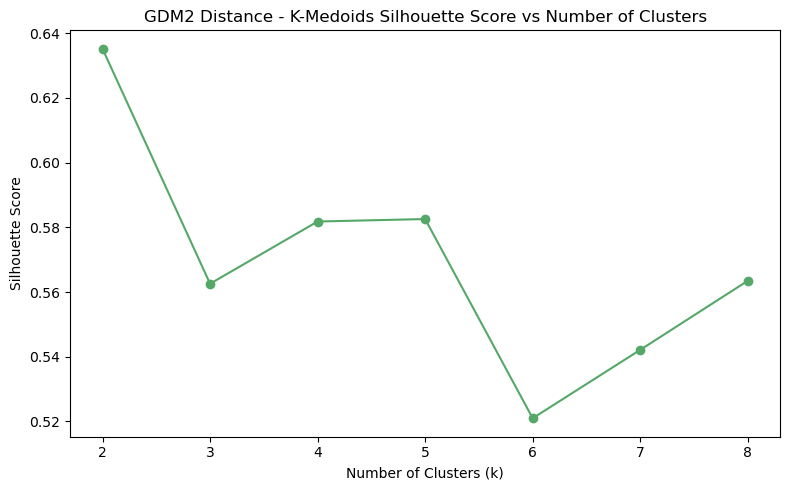

In [45]:
#Choose k for GDM2-based K-Medoids using silhouette score
gdm2_scores = {}
 
for k in range(2, 9):
    result = kmedoids.pam(gdm2_dist, k)
    labels = result.labels
    score = silhouette_score(gdm2_dist, labels, metric="precomputed")
    gdm2_scores[k] = score
    print(f"k={k} -> Silhouette Score: {score:.4f}")
 
plt.figure(figsize=(8, 5))
plt.plot(list(gdm2_scores.keys()), list(gdm2_scores.values()), marker="o", color="#55A868")
plt.title("GDM2 Distance - K-Medoids Silhouette Score vs Number of Clusters")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.tight_layout()
plt.savefig("GDM2 KMedoids Silhouette Selection.png", dpi=300, bbox_inches="tight")
plt.show()
 

In [46]:
#Fit final GDM2 K-Medoids model with chosen k ---
k_gdm2 = max(gdm2_scores, key=gdm2_scores.get)
print("Chosen number of clusters for GDM2 K-Medoids:", k_gdm2)
 
gdm2_result = kmedoids.pam(gdm2_dist, k_gdm2)
gdm2_labels = gdm2_result.labels
 
gdm2_silhouette = silhouette_score(gdm2_dist, gdm2_labels, metric="precomputed")
gdm2_db = davies_bouldin_score(X_raw, gdm2_labels)  # same approximation as above
 
print(f"GDM2 K-Medoids (k={k_gdm2}) -> Silhouette: {gdm2_silhouette:.4f}, Davies-Bouldin: {gdm2_db:.4f}")
 
df["GDM2_Cluster"] = gdm2_labels

Chosen number of clusters for GDM2 K-Medoids: 2
GDM2 K-Medoids (k=2) -> Silhouette: 0.6352, Davies-Bouldin: 0.9654


In [47]:
# COMPARISON OF THE THREE DISTANCE MEASURES
 
#Build comparison table
distance_comparison = pd.DataFrame({
    "Distance Measure": ["Gower", "Podani (Ordinal-Gower)", "GDM2 (Walesiak)"],
    "Number of Clusters": [k_gower, k_podani, k_gdm2],
    "Silhouette Score": [gower_silhouette, podani_silhouette, gdm2_silhouette],
    "Davies-Bouldin Index (approx.)": [gower_db, podani_db, gdm2_db],
})
 
distance_comparison = distance_comparison.round(4)
distance_comparison

,Distance Measure,Number of Clusters,Silhouette Score,Davies-Bouldin Index (approx.)
0,Gower,2,0.5991,0.9645
1,Podani (Ordinal-Gower),2,0.6321,0.9870
2,GDM2 (Walesiak),2,0.6352,0.9654


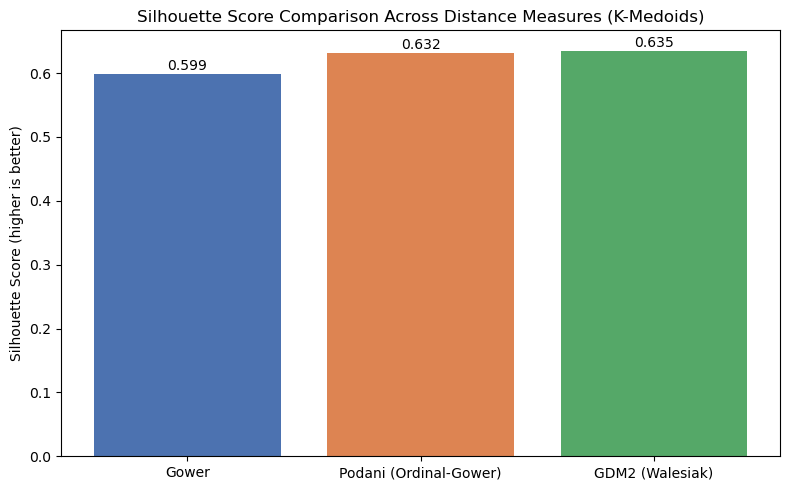

In [48]:
 #Visual comparison of silhouette scores across distances ---
plt.figure(figsize=(8, 5))
bars = plt.bar(distance_comparison["Distance Measure"], distance_comparison["Silhouette Score"],
               color=["#4C72B0", "#DD8452", "#55A868"])
 
plt.title("Silhouette Score Comparison Across Distance Measures (K-Medoids)")
plt.ylabel("Silhouette Score (higher is better)")
 
for i, v in enumerate(distance_comparison["Silhouette Score"]):
    plt.text(i, v + 0.005, f"{v:.3f}", ha="center")
 
plt.tight_layout()
plt.savefig("Distance Measure Comparison - Silhouette.png", dpi=300, bbox_inches="tight")
plt.show()

In [49]:
#Select the best-performing distance measure ---
best_distance = distance_comparison.loc[distance_comparison["Silhouette Score"].idxmax(), "Distance Measure"]
print("Best-performing distance measure based on Silhouette Score:", best_distance)
 
cluster_column_map = {
    "Gower": "Gower_Cluster",
    "Podani (Ordinal-Gower)": "Podani_Cluster",
    "GDM2 (Walesiak)": "GDM2_Cluster",
}
best_cluster_column = cluster_column_map[best_distance]
print("Cluster column to carry forward for segment profiling / Kruskal-Wallis / Chi-square:",
      best_cluster_column)
 

Best-performing distance measure based on Silhouette Score: GDM2 (Walesiak)
Cluster column to carry forward for segment profiling / Kruskal-Wallis / Chi-square: GDM2_Cluster


In [50]:
df["Best_Cluster"] = df[best_cluster_column]
df.head()

In [51]:
gower_cluster_sizes = df["Gower_Cluster"].value_counts().sort_index()
gower_cluster_sizes_pct = (gower_cluster_sizes / len(df) * 100).round(2)
 
print("Gower_Cluster sizes:")
print(gower_cluster_sizes)
print("\nGower_Cluster sizes (%):")
print(gower_cluster_sizes_pct)

Gower_Cluster sizes:
Gower_Cluster
0    2264
1     966
Name: count, dtype: int64

Gower_Cluster sizes (%):
Gower_Cluster
0    70.09
1    29.91
Name: count, dtype: float64


In [52]:
podani_cluster_sizes = df["Podani_Cluster"].value_counts().sort_index()
podani_cluster_sizes_pct = (podani_cluster_sizes / len(df) * 100).round(2)
 
print("Podani_Cluster sizes:")
print(podani_cluster_sizes)
print("\nPodani_Cluster sizes (%):")
print(podani_cluster_sizes_pct)

Podani_Cluster sizes:
Podani_Cluster
0    2183
1    1047
Name: count, dtype: int64

Podani_Cluster sizes (%):
Podani_Cluster
0    67.59
1    32.41
Name: count, dtype: float64


In [53]:
cluster_sizes = df["Best_Cluster"].value_counts().sort_index()
cluster_sizes_pct = (cluster_sizes / len(df) * 100).round(2)
 
print("Best_Cluster sizes:")
print(cluster_sizes)
print("\nBest_Cluster sizes (%):")
print(cluster_sizes_pct)

Best_Cluster sizes:
Best_Cluster
0    1966
1    1264
Name: count, dtype: int64

Best_Cluster sizes (%):
Best_Cluster
0    60.87
1    39.13
Name: count, dtype: float64


In [54]:
cluster_profile_median = df.groupby("Best_Cluster")[cluster_features].median()
cluster_profile_median 

,Welcome / Check in,Standard of the room,Cleanliness,Restaurant Service,Quality Meals,Attentiveness / Friendliness of Hotel staffs
Best_Cluster,,,,,,
0,4.0,4.0,4.0,4.0,4.0,4.0
1,3.0,3.0,3.0,3.0,3.0,3.0


In [55]:
cluster_profile_mode = df.groupby("Best_Cluster")[cluster_features].agg(
    lambda x: x.mode().iloc[0]
)
cluster_profile_mode_labels = cluster_profile_mode.applymap(lambda v: rating_labels[v])
cluster_profile_mode_labels

C:\Users\HP\AppData\Local\Temp\ipykernel_9292\759140092.py:4: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  cluster_profile_mode_labels = cluster_profile_mode.applymap(lambda v: rating_labels[v])


,Welcome / Check in,Standard of the room,Cleanliness,Restaurant Service,Quality Meals,Attentiveness / Friendliness of Hotel staffs
Best_Cluster,,,,,,
0,Excellent,Excellent,Excellent,Excellent,Excellent,Excellent
1,Good,Good,Good,Good,Good,Good


In [56]:
#Overall Rating comparison across clusters ---
overall_by_cluster = df.groupby("Best_Cluster")["Overall Rating"].agg(["mean", "median", "count"]).round(2)
overall_by_cluster

,mean,median,count
Best_Cluster,,,
0,3.90,4.0,1966
1,2.75,3.0,1264


Overall Rating,Unacceptable,Poor,Satisfactory,Good,Excellent
Best_Cluster,,,,,
0,0.0,0.1,0.4,9.3,90.2
1,1.2,5.1,19.6,65.7,8.4


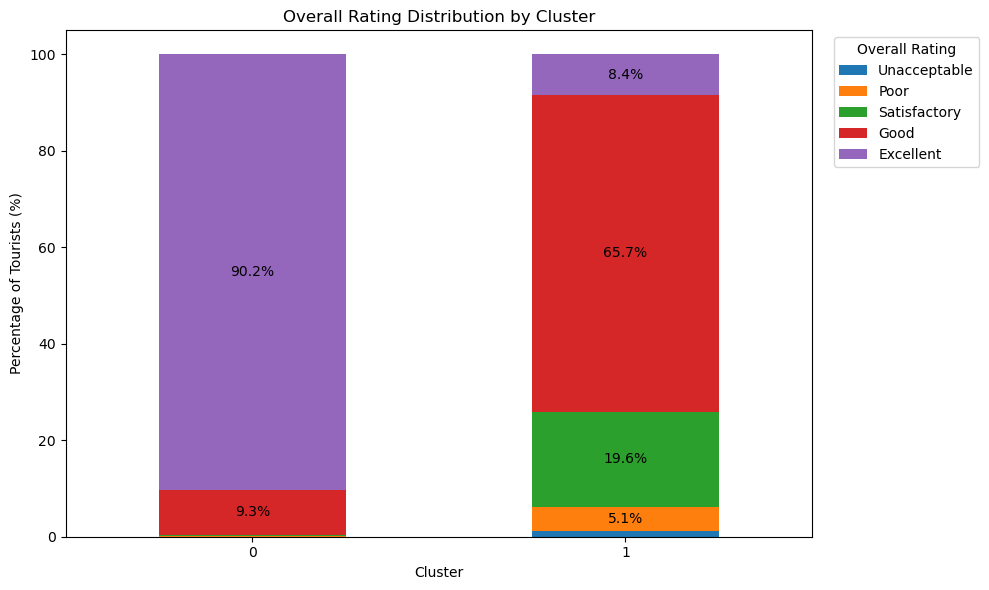

In [57]:

# Create percentage distribution of Overall Rating within each cluster
rating_distribution = pd.crosstab(df["Best_Cluster"],df["Overall Rating"],normalize="index") * 100

# Make sure all rating categories are present and in the correct order
rating_distribution = rating_distribution.reindex(columns=[0, 1, 2, 3, 4],fill_value=0)

# Rename categories
rating_distribution = rating_distribution.rename(columns=rating_labels)

# Display the percentages
display(rating_distribution.round(1))

ax = rating_distribution.plot(kind="bar",stacked=True,figsize=(10, 6))

# Add percentage labels inside each stack
for container in ax.containers:
    labels = [
        f"{bar.get_height():.1f}%"
        if bar.get_height() >= 3
        else ""
        for bar in container
    ]
    
    ax.bar_label(
        container,
        labels=labels,
        label_type="center"
    )

plt.title("Overall Rating Distribution by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Percentage of Tourists (%)")
plt.xticks(rotation=0)
plt.legend(title="Overall Rating",bbox_to_anchor=(1.02, 1),loc="upper left")

plt.tight_layout()
plt.savefig("Overall Rating Distribution by Cluster.png",dpi=300,bbox_inches="tight")

plt.show()

In [58]:
#  Top-Box / Bottom-Box analysis per feature, per cluster ---
# Top-Box = % rating Good (3) or Excellent (4)
# Bottom-Box = % rating Unacceptable (0) or Poor (1)

 
def top_box_pct(series):
    return (series >= 3).mean() * 100
 
def bottom_box_pct(series):
    return (series <= 1).mean() * 100
 
top_box = df.groupby("Best_Cluster")[cluster_features].agg(top_box_pct).round(1)
bottom_box = df.groupby("Best_Cluster")[cluster_features].agg(bottom_box_pct).round(1)
 
print("Top-Box % (Good + Excellent) by cluster:")
display(top_box)
 
print("\nBottom-Box % (Unacceptable + Poor) by cluster:")
display(bottom_box)
 

Top-Box % (Good + Excellent) by cluster:


,Welcome / Check in,Standard of the room,Cleanliness,Restaurant Service,Quality Meals,Attentiveness / Friendliness of Hotel staffs
Best_Cluster,,,,,,
0,99.4,98.8,99.6,99.6,98.6,99.7
1,86.3,72.2,78.6,74.3,69.2,84.5



Bottom-Box % (Unacceptable + Poor) by cluster:


,Welcome / Check in,Standard of the room,Cleanliness,Restaurant Service,Quality Meals,Attentiveness / Friendliness of Hotel staffs
Best_Cluster,,,,,,
0,0.2,0.1,0.1,0.0,0.1,0.1
1,2.4,6.9,4.8,5.4,7.0,3.1


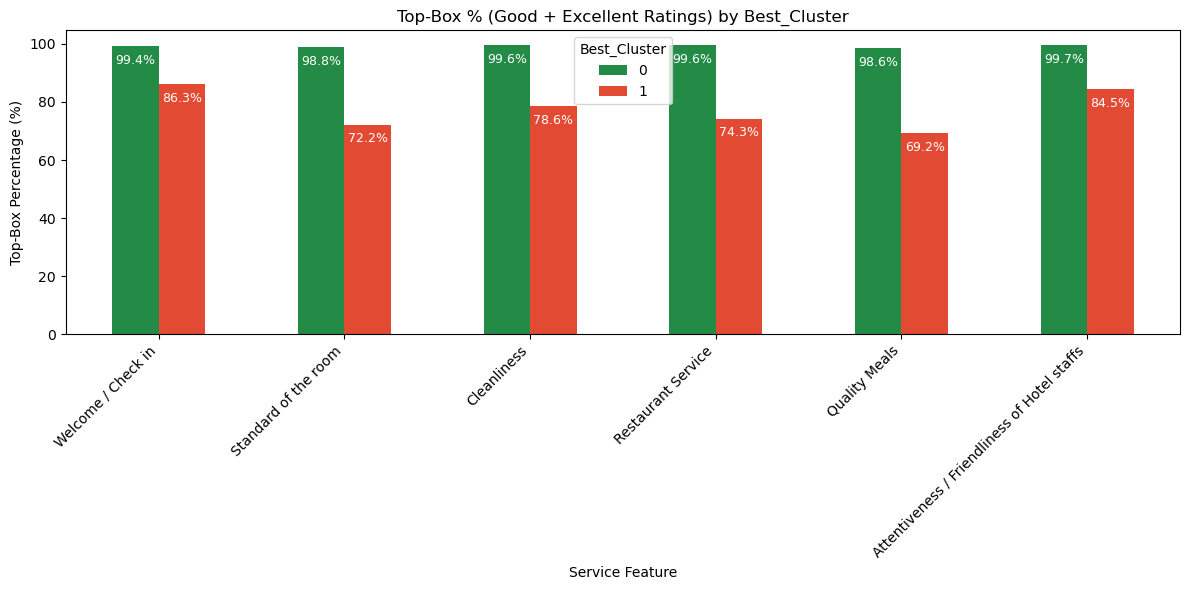

In [59]:
# Visualise Top-Box % by cluster
ax = top_box.T.plot(
    kind="bar",
    figsize=(12, 6),
    color=["#238b45", "#e34a33"]
)

plt.title("Top-Box % (Good + Excellent Ratings) by Best_Cluster")
plt.xlabel("Service Feature")
plt.ylabel("Top-Box Percentage (%)")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Best_Cluster")

# Add data labels inside the top of each bar
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        label_type="edge",
        padding=-15,
        fontsize=9,
        color="white"
    )

plt.tight_layout()
plt.savefig(
    "Top-Box Percentage by Best_Cluster.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [60]:
# Top-Box gap ranking (which features differentiate clusters most) ---
top_box_gap = (top_box.loc[0] - top_box.loc[1]).sort_values(ascending=False)
top_box_gap = top_box_gap.rename("Top-Box %% Gap (Cluster 0 - Cluster 1)")
top_box_gap

Quality Meals                                   29.4
Standard of the room                            26.6
Restaurant Service                              25.3
Cleanliness                                     21.0
Attentiveness / Friendliness of Hotel staffs    15.2
Welcome / Check in                              13.1
Name: Top-Box %% Gap (Cluster 0 - Cluster 1), dtype: float64

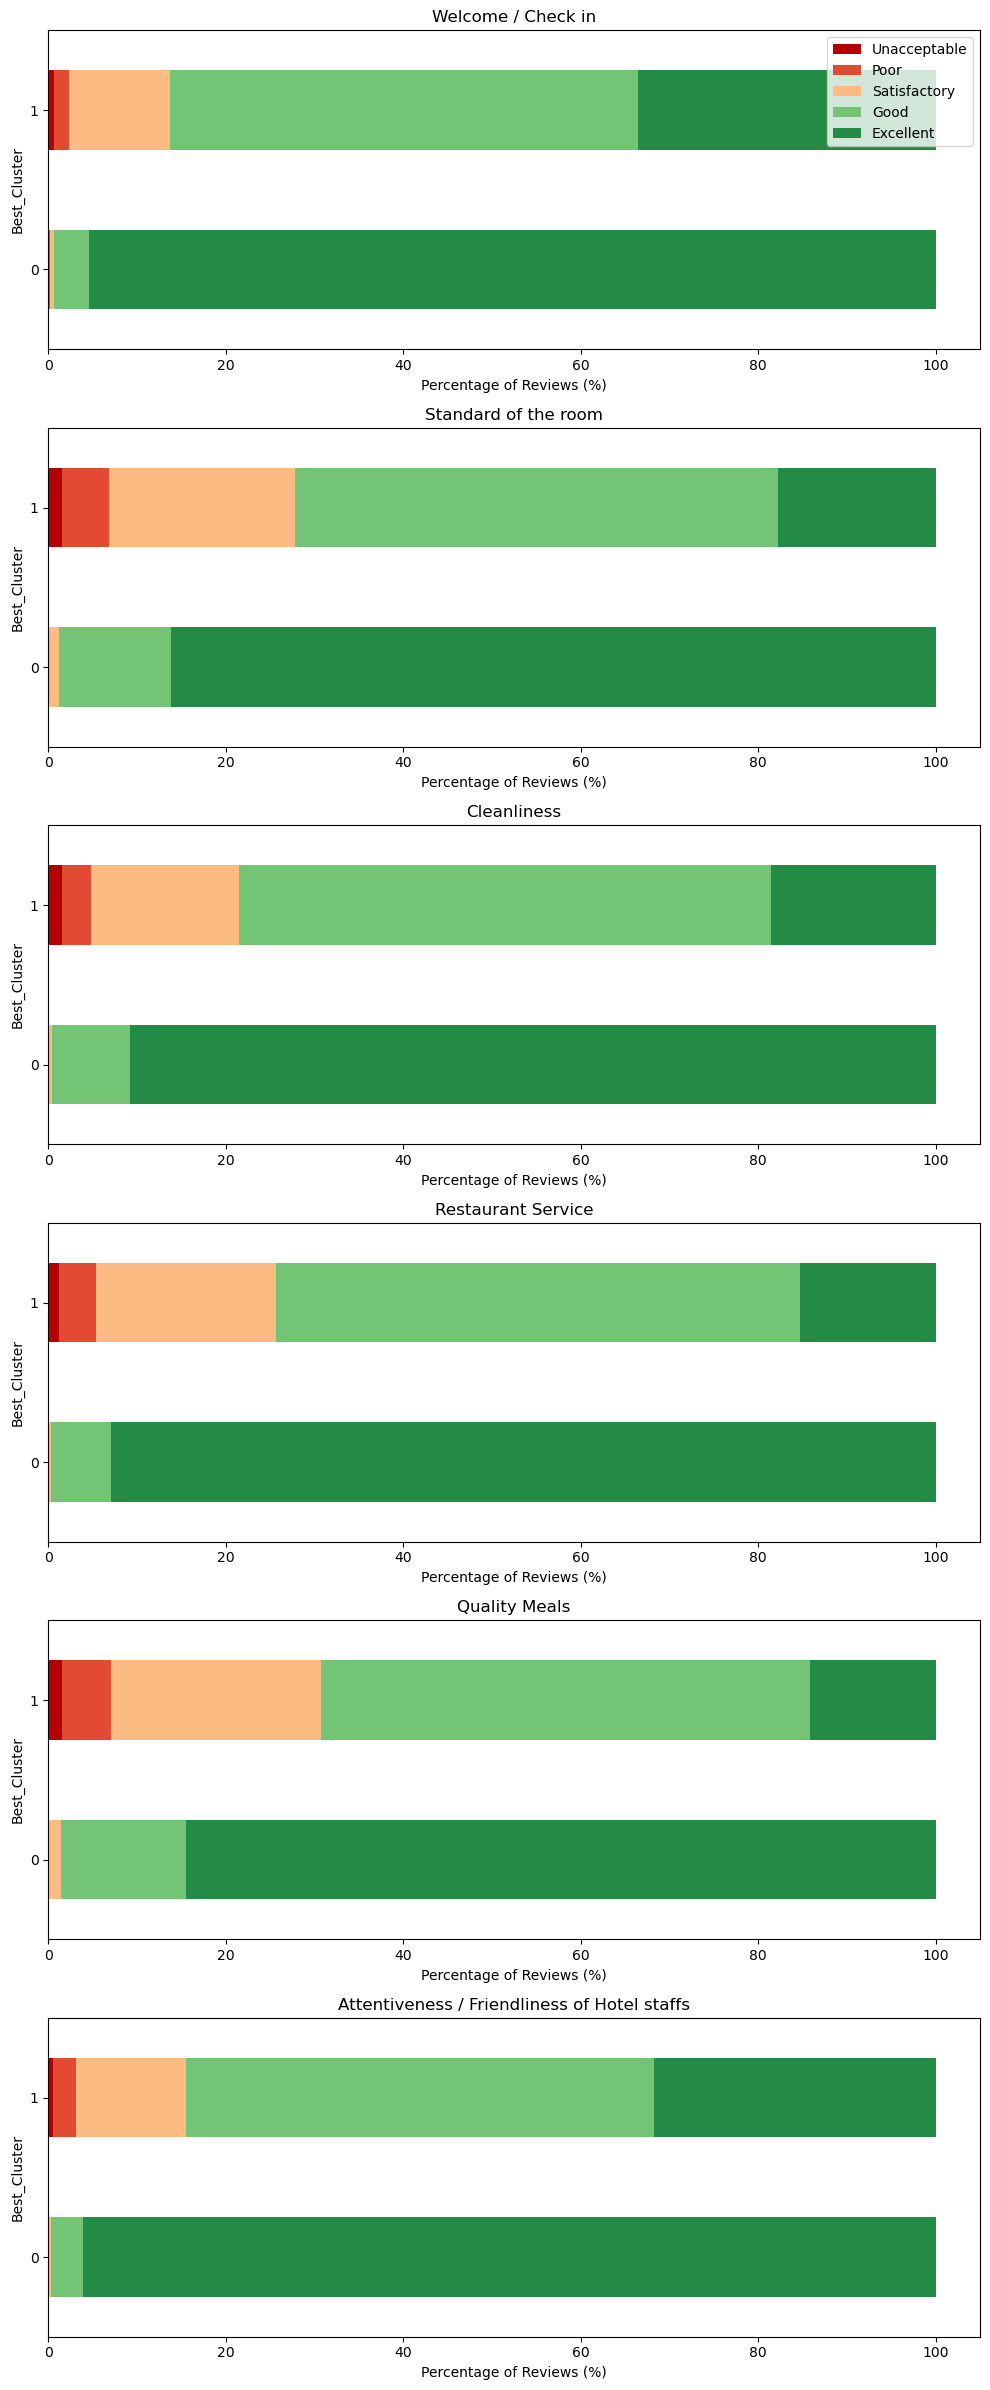

In [61]:
#Full ordinal distribution per feature, per cluster (stacked)
fig, axes = plt.subplots(len(cluster_features), 1, figsize=(10, 4 * len(cluster_features)))
 
for i, feature in enumerate(cluster_features):
    dist_by_cluster = pd.crosstab(df["Best_Cluster"], df[feature], normalize="index") * 100
    dist_by_cluster.columns = [rating_labels[c] for c in dist_by_cluster.columns]
    dist_by_cluster = dist_by_cluster.reindex(
        columns=["Unacceptable", "Poor", "Satisfactory", "Good", "Excellent"], fill_value=0
    )
    dist_by_cluster.plot(kind="barh", stacked=True,
                          color=["#b30000", "#e34a33", "#fdbb84", "#74c476", "#238b45"],
                          ax=axes[i], legend=(i == 0))
    axes[i].set_title(feature)
    axes[i].set_xlabel("Percentage of Reviews (%)")
    axes[i].set_ylabel("Best_Cluster")
 
plt.tight_layout()
plt.savefig("Rating Distribution by Feature and Cluster.png", dpi=300, bbox_inches="tight")
plt.show()

In [62]:
# KRUSKAL-WALLIS TEST
from scipy.stats import kruskal
# Run Kruskal-Wallis test for each service feature
kw_results = []
 
for feature in cluster_features + ["Overall Rating"]:
    group0 = df.loc[df["Best_Cluster"] == 0, feature]
    group1 = df.loc[df["Best_Cluster"] == 1, feature]
 
    h_stat, p_value = kruskal(group0, group1)
 
    kw_results.append({
        "Service Feature": feature,
        "H-Statistic": round(h_stat, 4),
        "p-value": p_value,
        "Significant (p < 0.05)": "Yes" if p_value < 0.05 else "No"
    })
 
kw_results_df = pd.DataFrame(kw_results)
kw_results_df["p-value (formatted)"] = kw_results_df["p-value"].apply(
    lambda p: "< 0.001" if p < 0.001 else f"{p:.4f}"
)
kw_results_df

,Service Feature,H-Statistic,p-value,Significant (p < 0.05),p-value (formatted)
0,Welcome / Check in,1416.8179,4.654468e-310,Yes,< 0.001
1,Standard of the room,1534.5401,0.000000e+00,Yes,< 0.001
2,Cleanliness,1721.2665,0.000000e+00,Yes,< 0.001
3,Restaurant Service,1966.9054,0.000000e+00,Yes,< 0.001
4,Quality Meals,1605.6400,0.000000e+00,Yes,< 0.001
5,Attentiveness / Friendliness of Hotel staffs,1532.1299,0.000000e+00,Yes,< 0.001
6,Overall Rating,2109.1595,0.000000e+00,Yes,< 0.001


In [63]:
# Effect size (epsilon-squared) - the ordinal-appropriate

n_total = len(df)
 
def epsilon_squared(h_stat, n):
    return h_stat / (n - 1)
 
kw_results_df["Epsilon-Squared"] = kw_results_df["H-Statistic"].apply(
    lambda h: round(epsilon_squared(h, n_total), 4)
)
 
kw_results_df_sorted = kw_results_df.sort_values("Epsilon-Squared", ascending=False)
kw_results_df_sorted[["Service Feature", "H-Statistic", "p-value (formatted)", "Epsilon-Squared"]]

,Service Feature,H-Statistic,p-value (formatted),Epsilon-Squared
6,Overall Rating,2109.1595,< 0.001,0.6532
3,Restaurant Service,1966.9054,< 0.001,0.6091
2,Cleanliness,1721.2665,< 0.001,0.5331
4,Quality Meals,1605.6400,< 0.001,0.4973
1,Standard of the room,1534.5401,< 0.001,0.4752
5,Attentiveness / Friendliness of Hotel staffs,1532.1299,< 0.001,0.4745
0,Welcome / Check in,1416.8179,< 0.001,0.4388


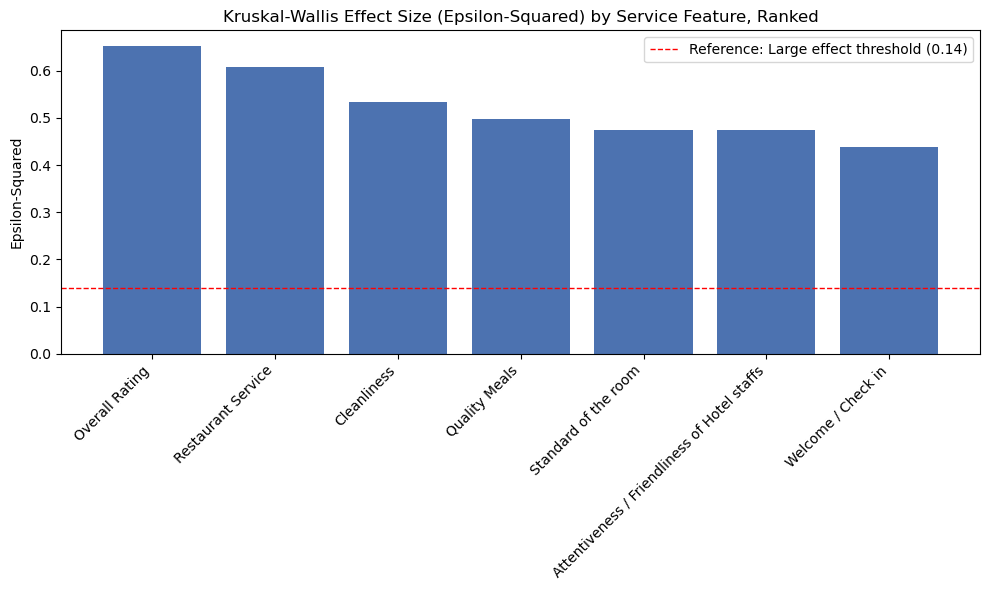

In [64]:
# Bar chart of effect sizes, ranked
plt.figure(figsize=(10, 6))
bars = plt.bar(kw_results_df_sorted["Service Feature"], kw_results_df_sorted["Epsilon-Squared"],
               color="#4C72B0")
 
plt.title("Kruskal-Wallis Effect Size (Epsilon-Squared) by Service Feature, Ranked")
plt.ylabel("Epsilon-Squared")
plt.xticks(rotation=45, ha="right")
plt.axhline(0.14, color="red", linestyle="--", linewidth=1, label="Reference: Large effect threshold (0.14)")
plt.legend()
 
plt.tight_layout()
plt.savefig("Kruskal-Wallis Effect Size Ranked.png", dpi=300, bbox_inches="tight")
plt.show()